# Problem 1
## Code to support answers in this cell is shown below:

#### a) Use 10 fold CV and evaluate pre-pruning rules to construct an individual classificaiton tree. Report the pre-pruning settings determined in the CV experiment and the corresponding value of the AUC. Compare the AUC of this pruned tree to the AUC of the full classification tree.
- The full tree shape is:
    - `Depth: 17`
    - `Leaves: 136`
    - `Nodes: 271`
- The AUC of the full tree is: `0.7704322848624929`
- The AUC of the pruned tree is: `0.8802046695474491`
- the best params of the pruned tree are:
    - `{'max_depth': 5, 'min_samples_leaf': 10}`
- pruning the tree with grid search improved AUC by about 0.11 so that is good

#### b) Using the best tree you found in previous step, predict what class a new customer falls into
- predicted to be 1 so they will churn

#### c) Construct RF model using 10 CV reporting settings determined and value of AUC (assuming train?)
- Best parameters via Grid Search: `{'max_features': 4, 'min_samples_leaf': 1, 'n_estimators': 100}`
- Best AUC: `0.9013005346568557`

#### d) Contruct a Gradient Boosted Ensemble. Report the best params from experiment and corresponding AUC
- best parameters via Grid Search: `{'learning_rate': 0.005, 'max_depth': 4, 'n_estimators': 300}`
- Best AUC: `0.8982346646717062`

#### e) Choose a final model, construct it on all data and report performance measures.
- The final model is Random Forest by just a hair. In reality, I would look at what the complexity/time is for scoring this as well as any explainability requirements before selecting it as my final model given that it was so close. However, for the sake of this class, we will use RF
- The confusion Matrix Metrics along with Accuracy, Precision, Recall and F1 are:
    - TN: `265`
    - FP: `6`
    - FN: `23`
    - TP: `51`
    - Accuracy score is: `0.9159420289855073`
    - Precision: `0.8947368421052632`
    - Recall: `0.6891891891891891`
    - F1: `0.7786259541984732`
- The AUC for the test is: `0.9064276453575347`
- The Lift is: `4.7`

#### f) Find the best threshold for the model (that isn't the default 0.5, essentially calibrating) that maximizes profit assuming a cost of retaining is worth 1000 and if they spend that, they always retain the customer
- Best threshold: 0.34, Maximum profit: 43400

#### g) Construct RF model (selected before) on full data and then score the new currentcustomers data with that. Based on probability threshold of 0.34, how many customers are likely to churn?
- Number likely to Churn: `395`
- List shown below

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)

cellphoneloc = "data/cellphonechurn.csv"
currentcustloc = "data/currentcustomers.csv"

In [2]:
df = pd.read_csv(cellphoneloc)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1721 entries, 0 to 1720
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer         1721 non-null   int64  
 1   Churn            1721 non-null   str    
 2   AccountWeeks     1721 non-null   int64  
 3   ContractRenewal  1721 non-null   int64  
 4   DataPlan         1721 non-null   int64  
 5   DataUsage        1721 non-null   float64
 6   CustServCalls    1721 non-null   int64  
 7   DayMins          1721 non-null   float64
 8   DayCalls         1721 non-null   int64  
 9   MonthlyCharge    1721 non-null   float64
 10  OverageFee       1721 non-null   float64
 11  RoamMins         1721 non-null   float64
dtypes: float64(5), int64(6), str(1)
memory usage: 161.5 KB


In [3]:
df.head()

,Customer,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,1330,No,63,1,0,0.27,3,211.8,84,58.7,11.55,10.7
1,782,No,82,1,0,0.21,0,135.4,102,46.1,11.86,17.5
2,1973,No,74,1,0,0.00,0,221.1,124,48.0,5.54,10.6
3,1821,No,74,1,0,0.00,1,165.3,120,45.0,9.93,9.8
4,768,No,137,1,0,0.23,1,155.5,81,40.3,6.66,9.1


In [4]:
df.describe()

,Customer,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
count,1721.000000,1721.000000,1721.000000,1721.000000,1721.000000,1721.000000,1721.00000,1721.000000,1721.000000,1721.000000,1721.000000
mean,1080.943056,100.323068,0.882045,0.278908,0.823492,1.650784,181.70645,100.339338,56.822371,10.120581,10.226845
std,618.801247,39.342846,0.322648,0.448592,1.285878,1.394575,56.17860,20.175074,16.666602,2.539562,2.844088
min,5.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,14.000000,2.110000,0.000000
25%,550.000000,74.000000,1.000000,0.000000,0.000000,1.000000,144.10000,87.000000,45.000000,8.380000,8.400000
50%,1076.000000,100.000000,1.000000,0.000000,0.000000,1.000000,181.50000,101.000000,54.000000,10.120000,10.300000
75%,1613.000000,125.000000,1.000000,1.000000,1.840000,2.000000,220.00000,114.000000,67.300000,11.840000,12.100000
max,2151.000000,243.000000,1.000000,1.000000,5.400000,9.000000,350.80000,165.000000,111.300000,18.090000,20.000000


In [5]:
df.isna().sum()

Customer           0
Churn              0
AccountWeeks       0
ContractRenewal    0
DataPlan           0
DataUsage          0
CustServCalls      0
DayMins            0
DayCalls           0
MonthlyCharge      0
OverageFee         0
RoamMins           0
dtype: int64

In [6]:
# transform churn column to binary target column

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# drop customer identifier

df = df.drop(columns=['Customer'])
df.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,63,1,0,0.27,3,211.8,84,58.7,11.55,10.7
1,0,82,1,0,0.21,0,135.4,102,46.1,11.86,17.5
2,0,74,1,0,0.00,0,221.1,124,48.0,5.54,10.6
3,0,74,1,0,0.00,1,165.3,120,45.0,9.93,9.8
4,0,137,1,0,0.23,1,155.5,81,40.3,6.66,9.1


In [7]:
df.describe()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
count,1721.000000,1721.000000,1721.000000,1721.000000,1721.000000,1721.000000,1721.00000,1721.000000,1721.000000,1721.000000,1721.000000
mean,0.219640,100.323068,0.882045,0.278908,0.823492,1.650784,181.70645,100.339338,56.822371,10.120581,10.226845
std,0.414123,39.342846,0.322648,0.448592,1.285878,1.394575,56.17860,20.175074,16.666602,2.539562,2.844088
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,14.000000,2.110000,0.000000
25%,0.000000,74.000000,1.000000,0.000000,0.000000,1.000000,144.10000,87.000000,45.000000,8.380000,8.400000
50%,0.000000,100.000000,1.000000,0.000000,0.000000,1.000000,181.50000,101.000000,54.000000,10.120000,10.300000
75%,0.000000,125.000000,1.000000,1.000000,1.840000,2.000000,220.00000,114.000000,67.300000,11.840000,12.100000
max,1.000000,243.000000,1.000000,1.000000,5.400000,9.000000,350.80000,165.000000,111.300000,18.090000,20.000000


In [8]:
# split the data into training and testing sets

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

X_train = train_df.drop(columns=['Churn'])
Y_train = train_df['Churn']
X_test = test_df.drop(columns=['Churn'])
Y_test = test_df['Churn']

## Part A (mostly)

In [9]:
# Perform 10-fold stratified cross-validation on the full decision tree model
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

full_tree = DecisionTreeClassifier(random_state=42)

full_scores = cross_val_score(full_tree, X_train, Y_train, cv=cv, scoring="roc_auc")
full_auc = full_scores.mean()
print(full_auc)

0.7704322848624929


In [10]:
# look at the structure of the full decision tree so I can build my grid search
full_tree.fit(X_train, Y_train)

print("Depth:", full_tree.get_depth())
print("Leaves:", full_tree.get_n_leaves())
print("Nodes:", full_tree.tree_.node_count)

Depth: 21
Leaves: 150
Nodes: 299


In [11]:
tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={
        "max_depth": [3, 4, 5, 6, 8, 10, 15, 20, 25],
        "min_samples_leaf": [1, 2, 5, 10, 15, 20, 30, 50]
    },
    cv=cv,
    scoring="roc_auc",
)

tree_search.fit(X_train, Y_train)

print("Best Parameters", tree_search.best_params_)
print("Best Score", tree_search.best_score_)

Best Parameters {'max_depth': 5, 'min_samples_leaf': 10}
Best Score 0.8802046695474491


## Part B

In [13]:
# save best tree and output structure
best_tree = tree_search.best_estimator_
print("Depth:", best_tree.get_depth())
print("Leaves:", best_tree.get_n_leaves())
print("Nodes:", best_tree.tree_.node_count)

Depth: 5
Leaves: 22
Nodes: 43


In [14]:
# create new person to see if model thinks they'll churn

new_customer = pd.DataFrame([{
    "AccountWeeks": 40,
    "ContractRenewal": 1,
    "DataPlan": 1,
    "DataUsage": 0,
    "CustServCalls": 6,
    "DayMins": 82,
    "DayCalls": 123,
    "MonthlyCharge": 32,
    "OverageFee": 11,
    "RoamMins": 11,
}])[X_train.columns]

best_tree.predict(new_customer)

best_tree.predict_proba(new_customer)

print("Prediction:", best_tree.predict(new_customer))
print("Prediction Probabilities:", best_tree.predict_proba(new_customer))

Prediction: [1]
Prediction Probabilities: [[0. 1.]]


## Part C

In [15]:
rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid={
        "n_estimators": [50, 100, 200, 300],
        "max_features": [2, 3, 4, 5, 6],
        "min_samples_leaf": [1, 2, 5, 10]
    },
    cv=cv,
    scoring="roc_auc",
)
rf_search.fit(X_train, Y_train)

print("Best Parameters", rf_search.best_params_)
print("Best Score", rf_search.best_score_)

Best Parameters {'max_features': 4, 'min_samples_leaf': 1, 'n_estimators': 100}
Best Score 0.9013005346568557


In [16]:
# save best rf
best_rf = rf_search.best_estimator_

## Part D

In [17]:
gb_search = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid={
        "n_estimators": [100, 200, 300, 400],
        "learning_rate": [0.005, 0.01, 0.02, 0.05],
        "max_depth": [2, 3, 4, 5, 6],
    },
    cv=cv,
    scoring="roc_auc",
)

gb_search.fit(X_train, Y_train)

print("Best Parameters", gb_search.best_params_)
print("Best Score", gb_search.best_score_)

Best Parameters {'learning_rate': 0.005, 'max_depth': 4, 'n_estimators': 300}
Best Score 0.8982346646717062


In [18]:
# save best gb model

best_gb = gb_search.best_estimator_

## Part E

In [23]:
final_model = rf_search.best_estimator_

probs = final_model.predict_proba(X_test)[:, 1]   # check final_model.classes_ so column 1 is churn
preds = final_model.predict(X_test)

print("CV AUC:  ", rf_search.best_score_)
print("Test AUC:", roc_auc_score(Y_test, probs))

tn, fp, fn, tp = confusion_matrix(Y_test, preds).ravel()
print(tn, fp, fn, tp)
print(f" The Accuracy score is: {accuracy_score(Y_test, preds)}, Precision: {precision_score(Y_test, preds)}, "
      f"Recall: {recall_score(Y_test, preds)}, F1: {f1_score(Y_test, preds)}")

CV AUC:   0.9013005346568557
Test AUC: 0.9064276453575347
265 6 23 51
 The Accuracy score is: 0.9159420289855073, Precision: 0.8947368421052632, Recall: 0.6891891891891891, F1: 0.7786259541984732


In [24]:
lift_df = pd.DataFrame({"y": Y_test.values, "p": probs}).sort_values("p", ascending=False)
n = np.arange(1, len(lift_df) + 1)
lift_df["pct_contacted"] = n / len(lift_df)
lift_df["lift"] = (lift_df["y"].cumsum() / n) / lift_df["y"].mean()

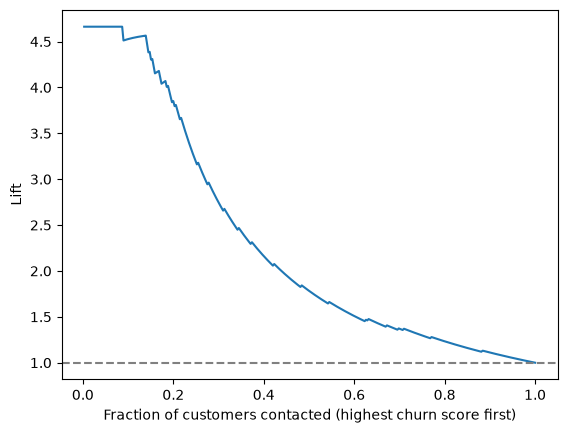

In [25]:
# charts generated with help from Claude
plt.plot(lift_df["pct_contacted"], lift_df["lift"])
plt.axhline(1, linestyle="--", color="gray")
plt.xlabel("Fraction of customers contacted (highest churn score first)")
plt.ylabel("Lift")
plt.show()

## Part F

In [28]:
# Turns into a profit analysis
# So we are finding two maximums being the best threshold and best profits

# Asked claude to help me construct a profit analysis code that gives me the best threshold with max profit
# This searches the different threshold spaces and reports back the best one
thresholds = np.linspace(0.01, 0.99, 99)
profits = []
for t in thresholds:
    flagged = probs >= t
    tp = ((flagged) & (Y_test == 1)).sum()
    fp = ((flagged) & (Y_test == 0)).sum()
    profits.append(tp * (1000 - 200) - fp * 200)

best_t = thresholds[np.argmax(profits)]
print(f"Best threshold: {best_t}, Maximum profit: {max(profits)}")

Best threshold: 0.34, Maximum profit: 43400


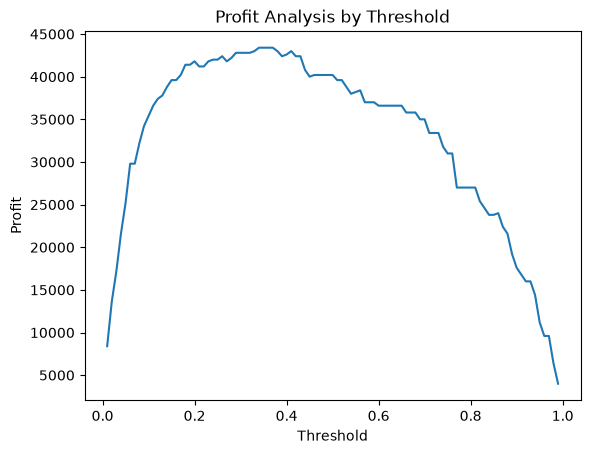

In [ ]:
# Charts generated with help from Claude to check output
plt.plot(thresholds, profits)
plt.xlabel("Threshold")
plt.ylabel("Profit")
plt.title("Profit Analysis by Threshold")
plt.show()

## Part G

In [ ]:
# Fit model to all data
X_all = df.drop(columns="Churn")
y_all = df["Churn"]

final_rf = RandomForestClassifier(**rf_search.best_params_, random_state=42)
final_rf.fit(X_all, y_all)

,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: b

In [31]:
currentcust = pd.read_csv(currentcustloc)

currentcust.head()

,Customer,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,2152,103,0,0,0.466381,2,131.1,101,50.8,9.57,12.8
1,2153,170,1,0,0.000000,2,228.2,146,66.0,11.44,10.3
2,2154,84,1,1,2.736847,4,107.0,118,69.5,13.77,5.2
3,2155,115,1,1,3.130690,4,160.2,119,73.1,16.17,11.9
4,2156,93,1,0,0.130865,7,136.4,93,49.7,11.73,3.6


In [32]:
currentcust.info()

<class 'pandas.DataFrame'>
RangeIndex: 529 entries, 0 to 528
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer         529 non-null    int64  
 1   AccountWeeks     529 non-null    int64  
 2   ContractRenewal  529 non-null    int64  
 3   DataPlan         529 non-null    int64  
 4   DataUsage        529 non-null    float64
 5   CustServCalls    529 non-null    int64  
 6   DayMins          529 non-null    float64
 7   DayCalls         529 non-null    int64  
 8   MonthlyCharge    529 non-null    float64
 9   OverageFee       529 non-null    float64
 10  RoamMins         529 non-null    float64
dtypes: float64(5), int64(6)
memory usage: 45.6 KB


In [33]:
# drop customer identifier

currentcust = currentcust.drop(columns=['Customer'])
currentcust.head()

,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,103,0,0,0.466381,2,131.1,101,50.8,9.57,12.8
1,170,1,0,0.000000,2,228.2,146,66.0,11.44,10.3
2,84,1,1,2.736847,4,107.0,118,69.5,13.77,5.2
3,115,1,1,3.130690,4,160.2,119,73.1,16.17,11.9
4,93,1,0,0.130865,7,136.4,93,49.7,11.73,3.6


In [35]:
current_probs = final_rf.predict_proba(currentcust[X_all.columns])[:, 1]
currentcust["churn_prob"] = current_probs

currentcust.head(10)

,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins,churn_prob
0,103,0,0,0.466381,2,131.1,101,50.8,9.57,12.8,0.50
1,170,1,0,0.000000,2,228.2,146,66.0,11.44,10.3,0.54
2,84,1,1,2.736847,4,107.0,118,69.5,13.77,5.2,0.62
3,115,1,1,3.130690,4,160.2,119,73.1,16.17,11.9,0.45
4,93,1,0,0.130865,7,136.4,93,49.7,11.73,3.6,0.63
5,121,1,0,0.000000,6,263.1,98,57.0,15.83,14.0,0.24
6,126,1,0,0.000000,9,153.9,118,41.0,11.09,9.8,0.93
7,189,1,1,4.108867,8,138.2,121,91.6,4.78,14.4,0.77
8,175,1,0,0.239156,9,242.5,131,63.2,7.21,9.1,0.44
9,45,1,0,0.000000,11,264.3,107,65.0,15.03,15.3,0.84


In [39]:
threshold = 0.34

offer = (currentcust["churn_prob"] > threshold).sum()

print(f"Number of customers likely to churn: {offer}")

Number of customers likely to churn: 395


In [37]:
top10 = currentcust.nlargest(10, "churn_prob")
top10.head()

,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins,churn_prob
439,35,1,0,0.000000,441,136.8,88,38.0,9.11,12.0,0.99
32,91,1,0,0.009373,33,136.4,112,41.0,7.62,7.4,0.98
36,107,1,0,0.079611,41,118.9,100,38.0,10.70,10.1,0.98
47,77,1,0,0.066110,48,134.0,112,32.0,8.72,11.1,0.98
83,122,1,0,0.091558,84,130.1,134,35.0,6.21,9.3,0.98
